<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** uRNA burden relative to the intracellular transcriptome by coarse cell type, across datasets (lambda = 0.5).
> - **Manuscript panels:** Reviewer response (lambda robustness across tissues)
> - **Inputs:** Outputs of `recompute_source_score.py` / `annotate_cell_type_general.py`
> - **Outputs:** Heatmaps and violins in `figures/`
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# uRNA burden relative to intracellular transcriptome, by unified coarse cell type

## Recap: how we got here

This notebook is the final step of a multi-part pipeline built to answer a reviewer question about the robustness of the exponential distance-decay parameter (λ) used in `troutpy`'s cell-centric uRNA source-score computation:

1. **λ robustness sweep** (see `notebooks/SUPP_3_hyperparameter_tuning_lambda/`, `notebooks/4_detailed_analysis/recompute_lambda_scores_msbrain.py`): swept λ ∈ {0.1, 0.25, 0.5, 1.0} with the production `troutpy.tl.urna_source_score` scorer (not the notebook's earlier throwaway prototype) on the full xenium_msbrain_5k dataset. λ=0.5 was the entropy-minimizing, concordance-plateau choice — λ=0.1 (the prior default) was the least stable setting tested.
2. **Production rerun at λ=0.5** for xenium_msbrain_5k (`notebooks/4_detailed_analysis/recompute_source_score_final_lambda05.py`) and for 16 other datasets in this repo's `rois/rois/` collection (`recompute_source_score.py` in this folder), each writing a new zarr and leaving the original untouched.
3. **Coarse, cross-dataset-comparable cell-type annotation** (`annotate_cell_type_general.py`): 14 of those datasets only had Leiden clusters, no biological cell-type label. Each was annotated with a `cell_type_general` column via a hybrid method — CellTypist's `Immune_All_High.pkl` model (majority-voted per Leiden cluster) for immune calls, and local marker-gene scoring (`coarse_marker_sets.py`: Epithelial, Endothelial, Fibroblast/Stromal, Muscle, Neural) for everything else. 3 datasets (atera_hsbreast, xenium_hsfemur, xenium_msbrain_5k) already had a real fine-grained `cell_type`, which was instead mapped down to the same coarse vocabulary by hand (`fine_to_coarse_mapping.py`).
4. **Malignant vs. normal epithelial cells are deliberately *not* distinguished.** Only atera_hsbreast's fine annotation could support that split; the other cancer-containing datasets (cosmx_hgsoc, cosmx_melanoma, cosmx_stomach, xenium_opsc_5k/v1, xenium_hsprostate) went through the generic marker-score method, which has no way to tell malignant from normal epithelial cells. Keeping the distinction for one dataset out of several would make `cell_type_general` *less* comparable across datasets, not more — so all tumor/malignant cells are folded into `Epithelial` everywhere.

All 17 datasets now carry the same `urna_source_score` (λ=0.5) and `cell_type_general` vocabulary.

## What this notebook adds

The earlier QC pass (`urna_by_celltype_summary.py`) asked "what % of a dataset's *total* assigned uRNA lands on each cell type" — a measure of where the uRNA budget goes, but not of how much uRNA burden any individual cell of that type actually carries relative to its own transcriptome.

This notebook asks a different, more directly interpretable question instead:

> **For a cell of a given coarse type, how large is its assigned extracellular (uRNA) signal relative to its own intracellular transcript count?**

Concretely, per cell:

$$\text{uRNA burden (\%)} = 100 \times \frac{\text{urna\_source\_score}}{\text{n\_counts (intracellular transcripts)}}$$

e.g. an astrocyte with 50 intracellular transcripts and 50 assigned uRNA transcripts has a uRNA burden of 100%. We then take the **mean of this per-cell ratio** within each (dataset, cell_type_general) group — not the ratio of the two group totals, which would be dominated by a handful of high-count cells.

`n_counts` was verified to equal the raw (pre-normalization) intracellular transcript count per cell (matches `table.layers['raw']` row sums exactly) — see the loading cell below.

**No confidence threshold is applied.** `urna_source_score` sums every assigned extracellular transcript's *best* (argmax) assignment score into its parent cell, regardless of how low that score is -- there is no minimum-confidence floor here. This is different from the `min_score=0.2` used purely for *visualization* in notebook 5's `spatial_transcripts_source(..., min_score=0.2)` calls (which only controls which transcripts get drawn as a colored halo vs. gray background); that threshold never touches `urna_source_score` itself or this burden metric.

**On axis scaling:** none of the plots below use a log scale. Per-cell uRNA burden is heavy-tailed (a handful of cells can have very high values), so a few panels cap the visible y-range at a percentile of the plotted data to keep the bulk of the distribution legible -- this is called out explicitly wherever it's done, and the full uncapped data is always in the saved CSVs.


## 1. Setup

In [1]:
import zarr
import numpy as np
import pandas as pd
import matplotlib

matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42
import matplotlib.pyplot as plt
import seaborn as sns

FIGURES_DIR = "/ictstr01/home/icb/sergio.salas/notebooks/troutpy_reproducibility/troutpy_reproducibility/notebooks/6_multi_dataset_lambda05_annotation/figures"

# (dataset_name, path to its final zarr carrying urna_source_score, n_counts, cell_type_general, X_umap)
FINAL_ZARRS = [
    ("xenium_msbrain_5k", "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_msbrain_5k/data_annotated_lambda0.5_unified.zarr"),
    ("atera_hsbreast", "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/atera_hsbreast/data_annotated_source_score_lambda0.5_unified.zarr"),
    ("xenium_hsfemur", "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_hsfemur/data_with_source_score_annotated_source_score_lambda0.5_unified.zarr"),
    ("cosmx_hgsoc", "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/cosmx_hgsoc/data_with_source_score_general_annotated_source_score_lambda0.5.zarr"),
    ("cosmx_melanoma", "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/cosmx_melanoma/data_with_source_score_general_annotated_source_score_lambda0.5.zarr"),
    ("cosmx_mousebrain", "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/cosmx_mousebrain/data_with_source_score_general_annotated_source_score_lambda0.5.zarr"),
    ("cosmx_stomach", "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/cosmx_stomach/data_with_source_score_general_annotated_source_score_lambda0.5.zarr"),
    ("merscope_hsbrain", "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/merscope_hsbrain/data_with_source_score_general_annotated_source_score_lambda0.5.zarr"),
    ("merscope_hsuterine", "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/merscope_hsuterine/data_with_source_score_general_annotated_source_score_lambda0.5.zarr"),
    ("xenium_hsheart", "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_hsheart/data_with_source_score_general_annotated_source_score_lambda0.5.zarr"),
    ("xenium_hsprostate", "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_hsprostate/data_with_source_score_general_annotated_source_score_lambda0.5.zarr"),
    ("xenium_hsputamen", "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_hsputamen/data_with_source_score_general_annotated_source_score_lambda0.5.zarr"),
    ("xenium_hsskin_5k", "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_hsskin_5k/data_with_source_score_general_annotated_source_score_lambda0.5.zarr"),
    ("xenium_msbrain_300", "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_msbrain_300/data_with_source_score_general_annotated_source_score_lambda0.5.zarr"),
    ("xenium_mscolon_5k", "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_mscolon_5k/data_with_source_score_general_annotated_source_score_lambda0.5.zarr"),
    ("xenium_opsc_5k", "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_opsc_5k/data_with_source_score_general_annotated_source_score_lambda0.5.zarr"),
    ("xenium_opsc_v1", "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_opsc_v1/data_with_source_score_general_annotated_source_score_lambda0.5.zarr"),
]
DATASET_ORDER = [n for n, _ in FINAL_ZARRS]
CATEGORY_ORDER = ["Epithelial", "Endothelial", "Fibroblast/Stromal", "Muscle", "Neural", "Immune", "Other/Unclear"]
CATEGORY_PALETTE = dict(zip(CATEGORY_ORDER, sns.color_palette("tab10", n_colors=len(CATEGORY_ORDER))))


## 2. Load per-cell uRNA score, intracellular counts, cell type, and UMAP coordinates for all 17 datasets

Reads `table.obs['urna_source_score']`, `table.obs['n_counts']`, `table.obs['cell_type_general']`, and `table.obsm['X_umap']` directly via the zarr array API — this bypasses a full SpatialData parse (which also loads image DataTrees, the slow part of `sd.read_zarr` and unnecessary here).

In [2]:
def load_obs_fields(path):
    obs = zarr.open(f"{path}/tables/table/obs", mode="r")
    score = obs["urna_source_score"][:]
    n_counts = obs["n_counts"][:]
    ct = obs["cell_type_general"]
    categories = np.array(ct["categories"][:])
    codes = ct["codes"][:]
    labels = np.where(codes >= 0, categories[np.clip(codes, 0, len(categories) - 1)], "NA")

    obsm = zarr.open(f"{path}/tables/table/obsm", mode="r")
    umap = np.asarray(obsm["X_umap"][:, :2])

    return pd.DataFrame(
        {
            "urna_source_score": score,
            "n_counts": n_counts,
            "cell_type_general": labels,
            "umap_1": umap[:, 0],
            "umap_2": umap[:, 1],
        }
    )


# Sanity check (done once, interactively, before trusting n_counts as "intracellular transcripts"):
# table.obs['n_counts'] was confirmed to exactly equal table.layers['raw'] row sums on cosmx_hgsoc
# (e.g. cells 0-4: n_counts=[74,47,39,51,34], raw layer row sums=[74,47,39,51,34]) -- i.e. it is the
# raw, pre-normalization intracellular transcript count per cell, exactly what this metric needs.

per_cell_frames = []
for name, path in FINAL_ZARRS:
    print(f"[{name}] reading {path}", flush=True)
    df = load_obs_fields(path)
    df["dataset"] = name
    per_cell_frames.append(df)

per_cell = pd.concat(per_cell_frames, ignore_index=True)
per_cell = per_cell[per_cell["n_counts"] > 0].copy()
per_cell["urna_pct_of_intracellular"] = 100 * per_cell["urna_source_score"] / per_cell["n_counts"]
print(f"\nTotal cells across all 17 datasets: {len(per_cell):,}")
per_cell.head()


[xenium_msbrain_5k] reading /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_msbrain_5k/data_annotated_lambda0.5_unified.zarr


[atera_hsbreast] reading /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/atera_hsbreast/data_annotated_source_score_lambda0.5_unified.zarr


[xenium_hsfemur] reading /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_hsfemur/data_with_source_score_annotated_source_score_lambda0.5_unified.zarr


[cosmx_hgsoc] reading /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/cosmx_hgsoc/data_with_source_score_general_annotated_source_score_lambda0.5.zarr


[cosmx_melanoma] reading /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/cosmx_melanoma/data_with_source_score_general_annotated_source_score_lambda0.5.zarr


...

[xenium_mscolon_5k] reading /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_mscolon_5k/data_with_source_score_general_annotated_source_score_lambda0.5.zarr


[xenium_opsc_5k] reading /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_opsc_5k/data_with_source_score_general_annotated_source_score_lambda0.5.zarr


[xenium_opsc_v1] reading /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_opsc_v1/data_with_source_score_general_annotated_source_score_lambda0.5.zarr



Total cells across all 17 datasets: 207,624


,urna_source_score,n_counts,cell_type_general,umap_1,umap_2,dataset,urna_pct_of_intracellular
0,62.257846,876.0,Neural,-2.332013,-5.858753,xenium_msbrain_5k,7.107060
1,74.425582,1825.0,Immune,-3.381011,4.510523,xenium_msbrain_5k,4.078114
2,12.975060,1323.0,Neural,3.718663,-7.088686,xenium_msbrain_5k,0.980730
3,46.796027,978.0,Neural,3.647479,-6.433906,xenium_msbrain_5k,4.784870
4,15.044899,722.0,Neural,3.777481,-7.096349,xenium_msbrain_5k,2.083781


In [3]:
per_cell.to_csv(f"{FIGURES_DIR}/urna_burden_per_cell.csv.gz", index=False, compression="gzip")
print(f"Saved {FIGURES_DIR}/urna_burden_per_cell.csv.gz ({len(per_cell):,} cells)")


Saved /ictstr01/home/icb/sergio.salas/notebooks/troutpy_reproducibility/troutpy_reproducibility/notebooks/6_multi_dataset_lambda05_annotation/figures/urna_burden_per_cell.csv.gz (207,624 cells)


## 3. Cell type composition — what % of cells does each class represent, per dataset?

Before looking at uRNA burden, it matters how much of each dataset a given `cell_type_general` actually is — a mean burden based on 20 cells reads very differently than one based on 20,000. This table/heatmap is purely about **cell counts**, independent of uRNA score.

In [4]:
composition = (
    per_cell.groupby(["dataset", "cell_type_general"])
    .size()
    .rename("n_cells")
    .reset_index()
)
dataset_totals = composition.groupby("dataset")["n_cells"].transform("sum")
composition["pct_of_dataset_cells"] = 100 * composition["n_cells"] / dataset_totals
composition.to_csv(f"{FIGURES_DIR}/cell_type_composition.csv", index=False)
print(f"Saved {FIGURES_DIR}/cell_type_composition.csv")
composition.sort_values(["dataset", "cell_type_general"])


Saved /ictstr01/home/icb/sergio.salas/notebooks/troutpy_reproducibility/troutpy_reproducibility/notebooks/6_multi_dataset_lambda05_annotation/figures/cell_type_composition.csv


,dataset,cell_type_general,n_cells,pct_of_dataset_cells
0,atera_hsbreast,Endothelial,952,8.178694
1,atera_hsbreast,Epithelial,8142,69.948454
2,atera_hsbreast,Fibroblast/Stromal,1097,9.424399
3,atera_hsbreast,Immune,971,8.341924
4,atera_hsbreast,Muscle,478,4.106529
...,...,...,...,...
72,xenium_opsc_5k,Fibroblast/Stromal,2044,7.249769
73,xenium_opsc_5k,Immune,21122,74.916649
74,xenium_opsc_v1,Endothelial,2424,10.240379
75,xenium_opsc_v1,Epithelial,19450,82.168054


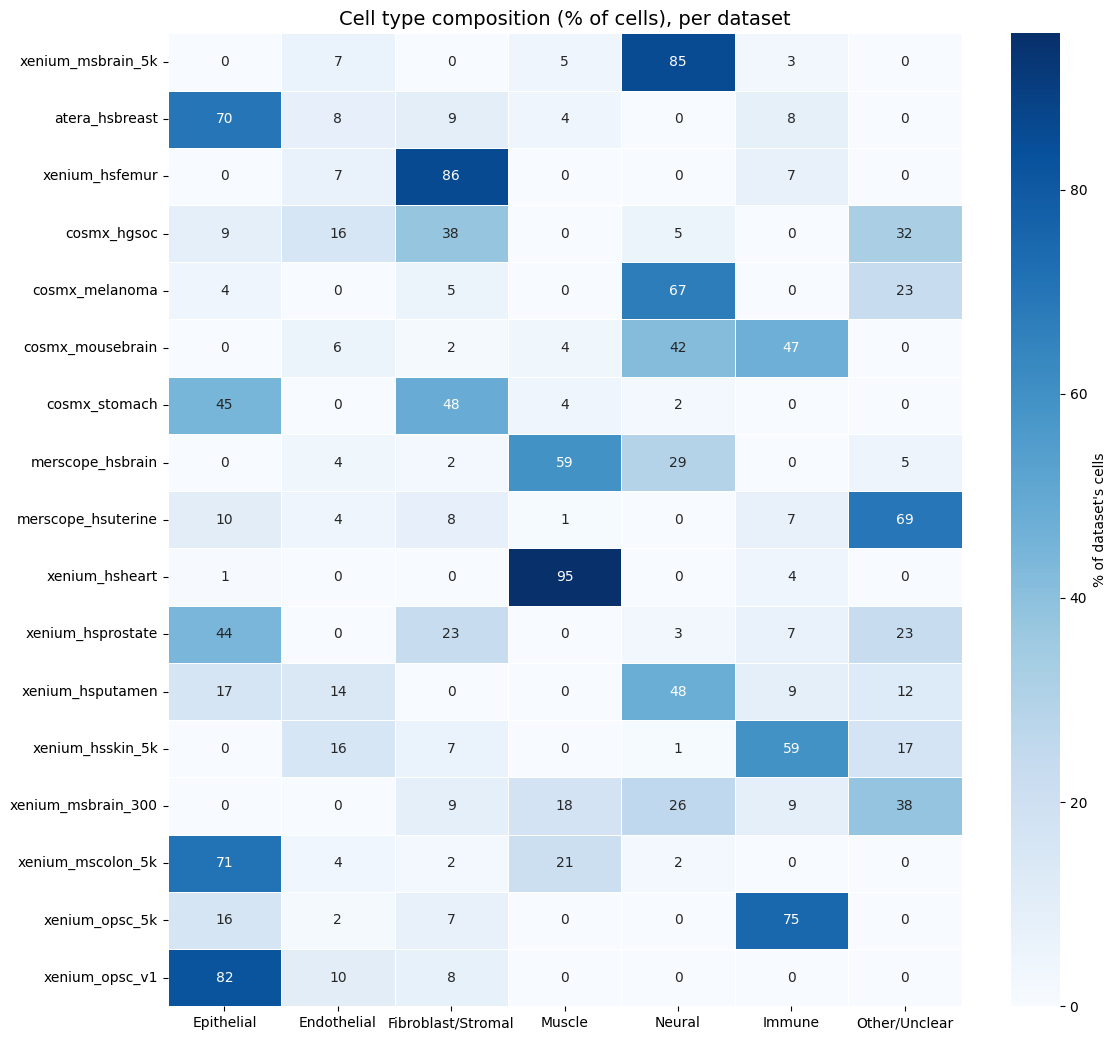

In [5]:
comp_pivot = composition.pivot(index="dataset", columns="cell_type_general", values="pct_of_dataset_cells").fillna(0)
comp_pivot = comp_pivot[[c for c in CATEGORY_ORDER if c in comp_pivot.columns]].loc[DATASET_ORDER]

fig, ax = plt.subplots(figsize=(1.4 * comp_pivot.shape[1] + 2, 0.5 * comp_pivot.shape[0] + 2))
sns.heatmap(
    comp_pivot, annot=True, fmt=".0f", cmap="Blues",
    cbar_kws={"label": "% of dataset's cells"},
    linewidths=0.5, linecolor="white", ax=ax,
)
ax.set_title("Cell type composition (% of cells), per dataset", fontsize=14)
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/cell_type_composition_heatmap.pdf", bbox_inches="tight")
plt.show()


## 4. Aggregate: mean uRNA burden (%) per cell type, per dataset

In [6]:
summary = (
    per_cell.groupby(["dataset", "cell_type_general"])["urna_pct_of_intracellular"]
    .agg(n_cells="size", mean_pct="mean", median_pct="median", std_pct="std")
    .reset_index()
)
summary.to_csv(f"{FIGURES_DIR}/urna_burden_summary.csv", index=False)
print(f"Saved {FIGURES_DIR}/urna_burden_summary.csv")
summary.sort_values(["dataset", "cell_type_general"])


Saved /ictstr01/home/icb/sergio.salas/notebooks/troutpy_reproducibility/troutpy_reproducibility/notebooks/6_multi_dataset_lambda05_annotation/figures/urna_burden_summary.csv


,dataset,cell_type_general,n_cells,mean_pct,median_pct,std_pct
0,atera_hsbreast,Endothelial,952,8.987561,7.754311,6.149513
1,atera_hsbreast,Epithelial,8142,6.533246,4.372437,7.168857
2,atera_hsbreast,Fibroblast/Stromal,1097,10.831549,9.179610,6.677742
3,atera_hsbreast,Immune,971,8.157312,6.655824,6.156774
4,atera_hsbreast,Muscle,478,9.550402,8.173729,6.426375
...,...,...,...,...,...,...
72,xenium_opsc_5k,Fibroblast/Stromal,2044,7.319663,5.741031,5.859047
73,xenium_opsc_5k,Immune,21122,5.384540,3.527489,6.216591
74,xenium_opsc_v1,Endothelial,2424,10.565102,6.654469,13.090327
75,xenium_opsc_v1,Epithelial,19450,5.596212,3.241408,7.690897


## 5. Visualization A — Heatmap: mean uRNA burden (%) by cell type × dataset

Quick global overview: which (dataset, cell type) combinations carry the highest mean uRNA-to-intracellular-transcript ratio.

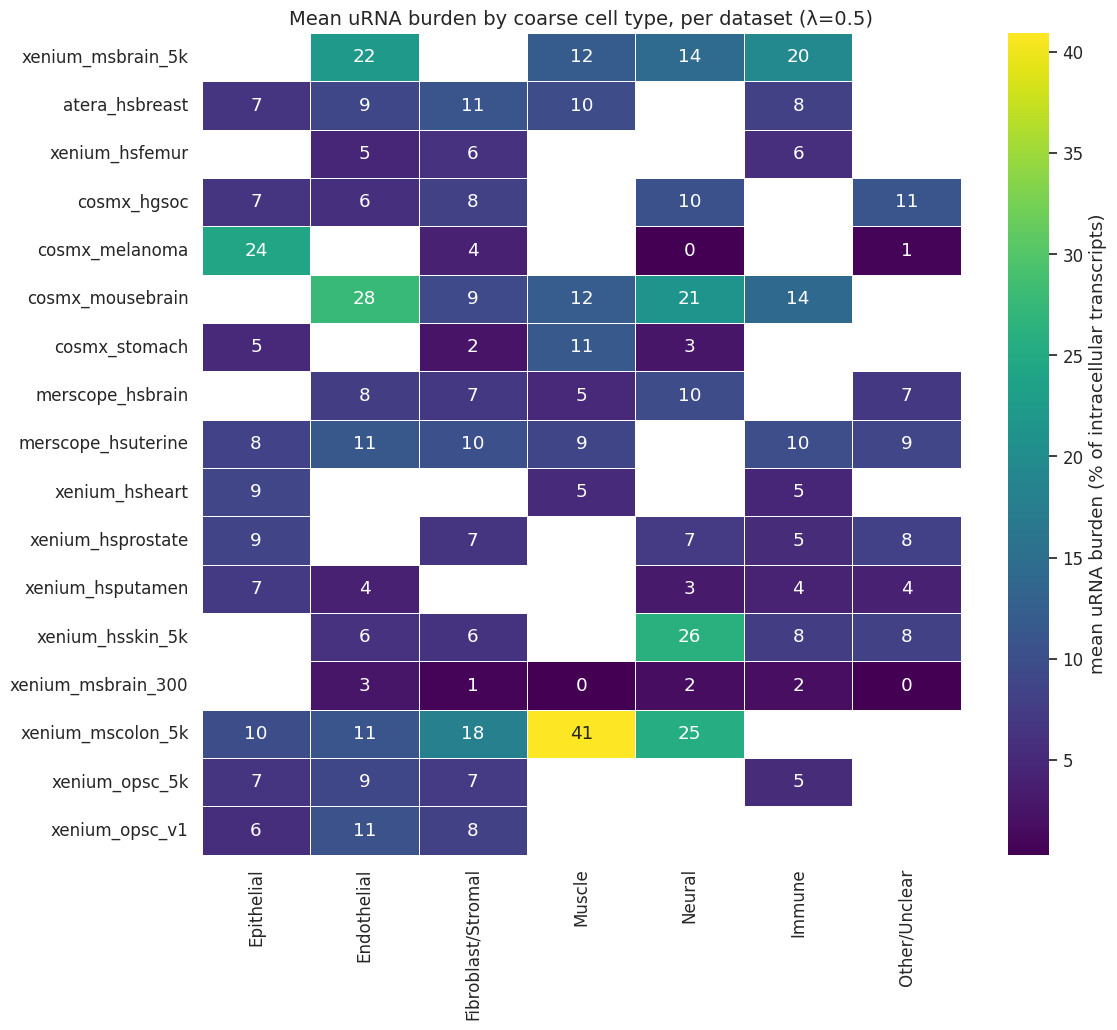

In [7]:
pivot = summary.pivot(index="dataset", columns="cell_type_general", values="mean_pct")
pivot = pivot[[c for c in CATEGORY_ORDER if c in pivot.columns]].loc[DATASET_ORDER]

sns.set_theme(style="white", font_scale=1.1)
fig, ax = plt.subplots(figsize=(1.4 * pivot.shape[1] + 2, 0.5 * pivot.shape[0] + 2))
sns.heatmap(
    pivot, annot=True, fmt=".0f", cmap="viridis",
    cbar_kws={"label": "mean uRNA burden (% of intracellular transcripts)"},
    linewidths=0.5, linecolor="white", ax=ax,
)
ax.set_title("Mean uRNA burden by coarse cell type, per dataset (λ=0.5)", fontsize=14)
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/urna_burden_heatmap.pdf", bbox_inches="tight")
plt.show()


## 6. Visualization B — Per-dataset distributions (violin), same layout as the heatmap

Same row order as the heatmap above (one row per dataset), cell type on the x-axis — but showing the full per-cell distribution as a violin instead of collapsing to one mean per cell. Each row has its own y-axis (`sharey=False`): datasets differ hugely in score scale (some are in the single digits, others in the hundreds), so a shared axis would flatten most rows to invisibility. No log transform — axes are linear.

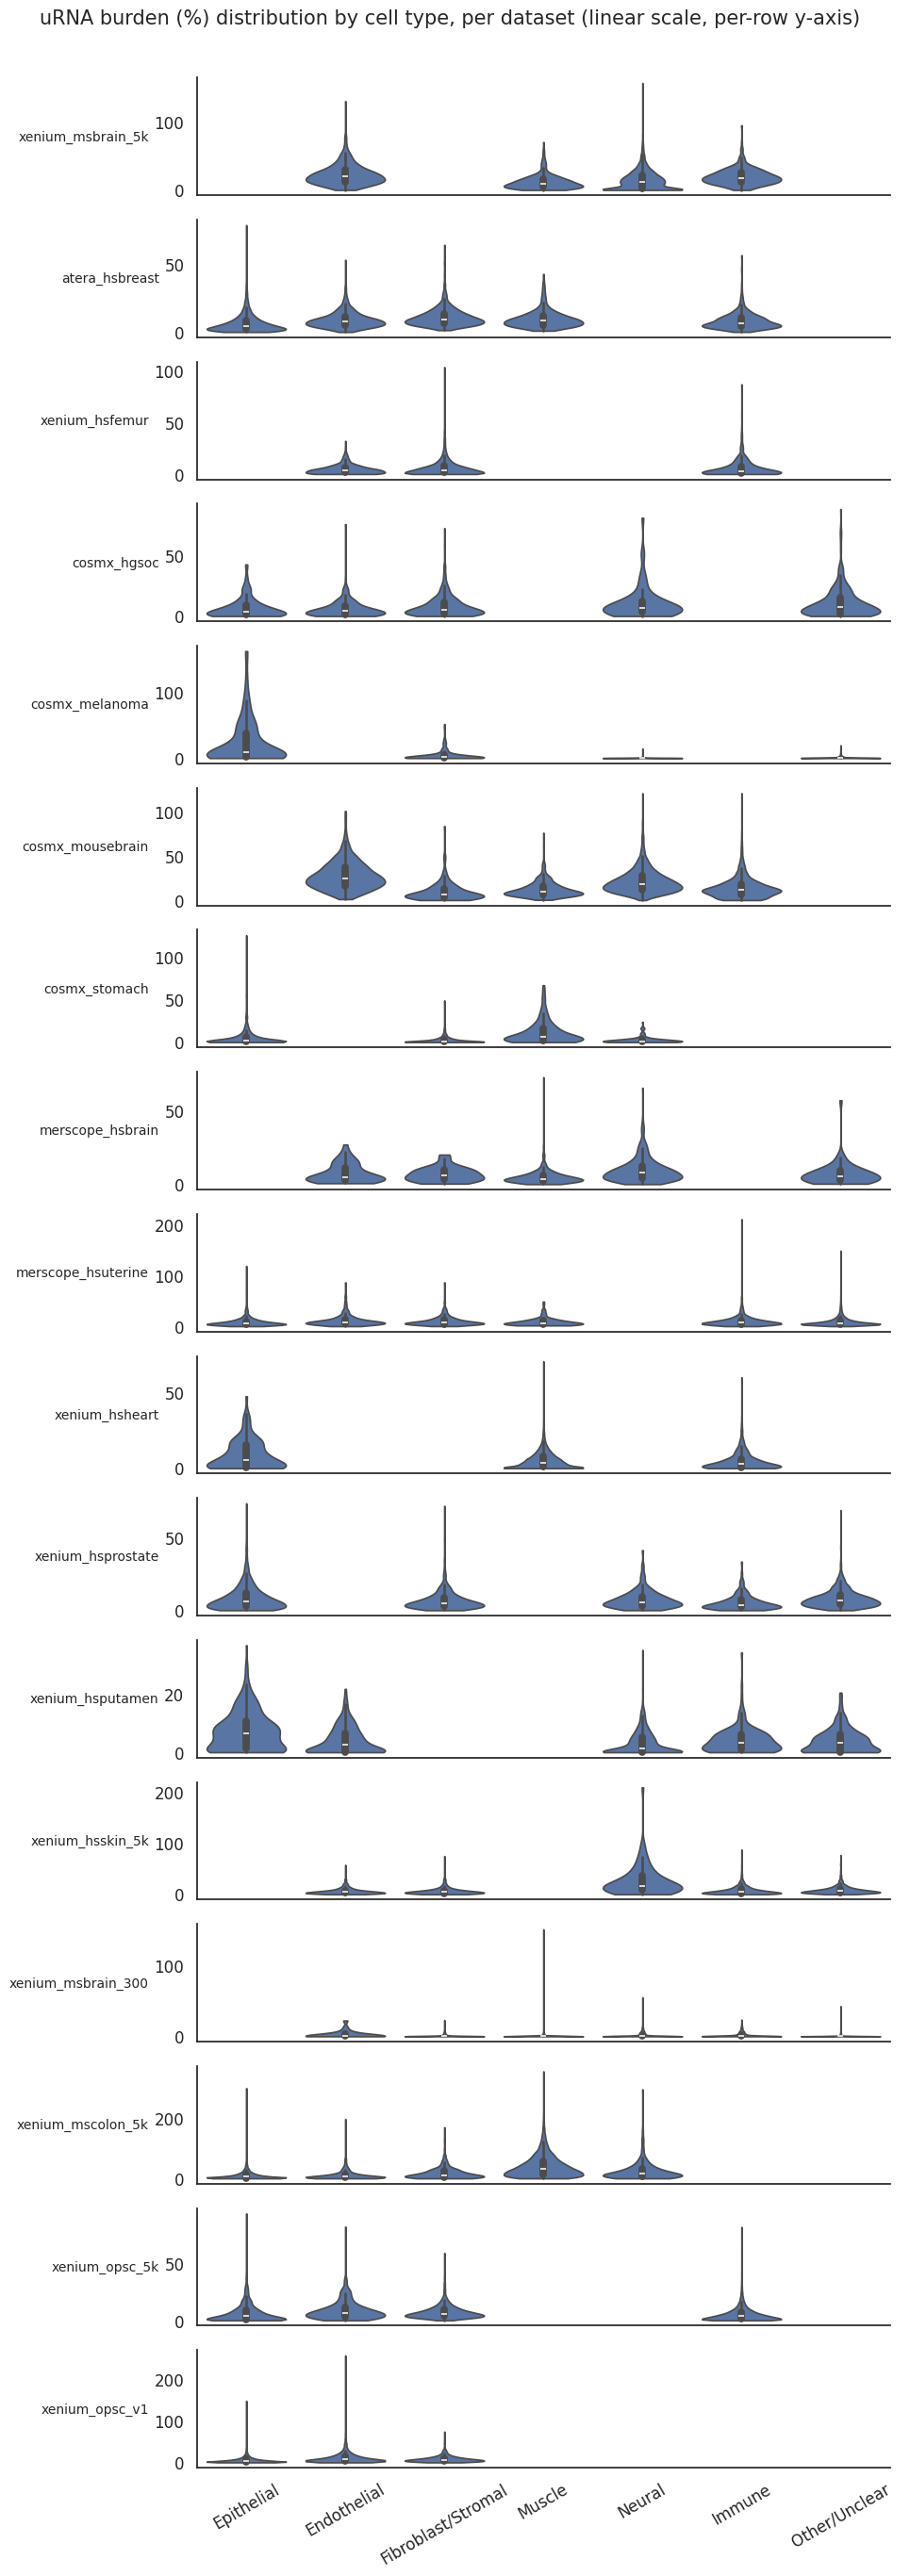

In [8]:
g = sns.catplot(
    data=per_cell, x="cell_type_general", y="urna_pct_of_intracellular",
    row="dataset", row_order=DATASET_ORDER, kind="violin",
    order=CATEGORY_ORDER, cut=0, density_norm="width",
    height=1.6, aspect=6, sharey=False,
)
for ax, name in zip(g.axes.flat, DATASET_ORDER):
    ax.set_title("")
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=10)
    ax.set_xlabel("")
g.axes.flat[-1].tick_params(axis="x", rotation=30)
g.figure.suptitle("uRNA burden (%) distribution by cell type, per dataset (linear scale, per-row y-axis)", y=1.005, fontsize=15)
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/urna_burden_violins_per_dataset.pdf", bbox_inches="tight")
plt.show()


## 7. Visualization C — Pooled distribution by cell type, across all datasets

Pools every cell of a given coarse type from all 17 datasets together: is uRNA burden generally higher for some cell types than others, independent of dataset/tissue/technology? Linear scale; y-axis capped at the 99th percentile of pooled values to keep the bulk of the distribution legible (a small number of higher-burden cells extend beyond the visible range — see `urna_burden_per_cell.csv.gz` for the uncapped data).

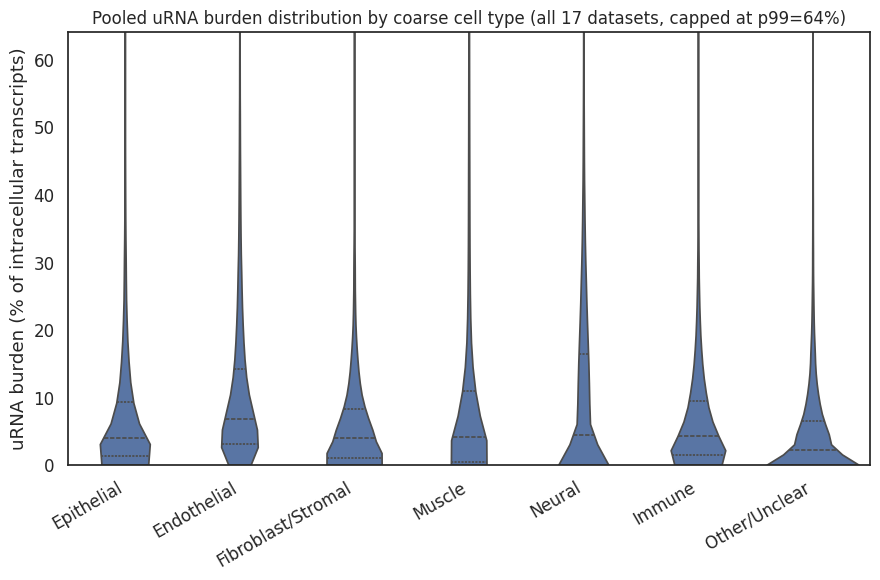

In [9]:
y_cap = np.percentile(per_cell["urna_pct_of_intracellular"], 99)

fig, ax = plt.subplots(figsize=(9, 6))
sns.violinplot(
    data=per_cell, x="cell_type_general", y="urna_pct_of_intracellular",
    order=CATEGORY_ORDER, cut=0, inner="quartile", ax=ax,
)
ax.set_ylim(0, y_cap)
ax.set_xlabel("")
ax.set_ylabel("uRNA burden (% of intracellular transcripts)")
ax.set_title(f"Pooled uRNA burden distribution by coarse cell type (all 17 datasets, capped at p99={y_cap:.0f}%)", fontsize=12)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/urna_burden_pooled_violin.pdf", bbox_inches="tight")
plt.show()


## 8. Visualization D — Cross-dataset consistency

For each coarse cell type, one point per dataset showing that dataset's mean uRNA burden for that type. Tight clusters mean a cell type's uRNA burden is consistent regardless of tissue/technology; spread-out points mean it varies a lot dataset-to-dataset (worth treating with more caution). Linear scale.

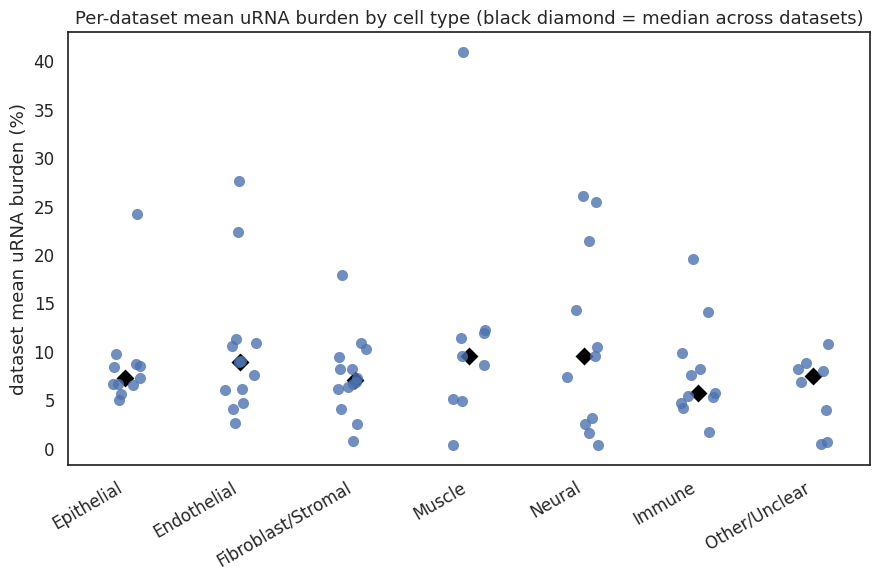

In [10]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.stripplot(
    data=summary, x="cell_type_general", y="mean_pct", order=CATEGORY_ORDER,
    size=8, jitter=0.15, alpha=0.8, ax=ax,
)
sns.pointplot(
    data=summary, x="cell_type_general", y="mean_pct", order=CATEGORY_ORDER,
    estimator="median", errorbar=None, color="black", markers="D", linestyle="none", ax=ax,
)
ax.set_xlabel("")
ax.set_ylabel("dataset mean uRNA burden (%)")
ax.set_title("Per-dataset mean uRNA burden by cell type (black diamond = median across datasets)", fontsize=13)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(f"{FIGURES_DIR}/urna_burden_cross_dataset_consistency.pdf", bbox_inches="tight")
plt.show()


## 9. UMAPs colored by cell_type_general

One UMAP per dataset (each dataset's own embedding, from the shared `clustering_pipeline`'s `sc.tl.umap` step — not a joint embedding across datasets), colored with the same category→color mapping throughout so colors mean the same thing in every panel.

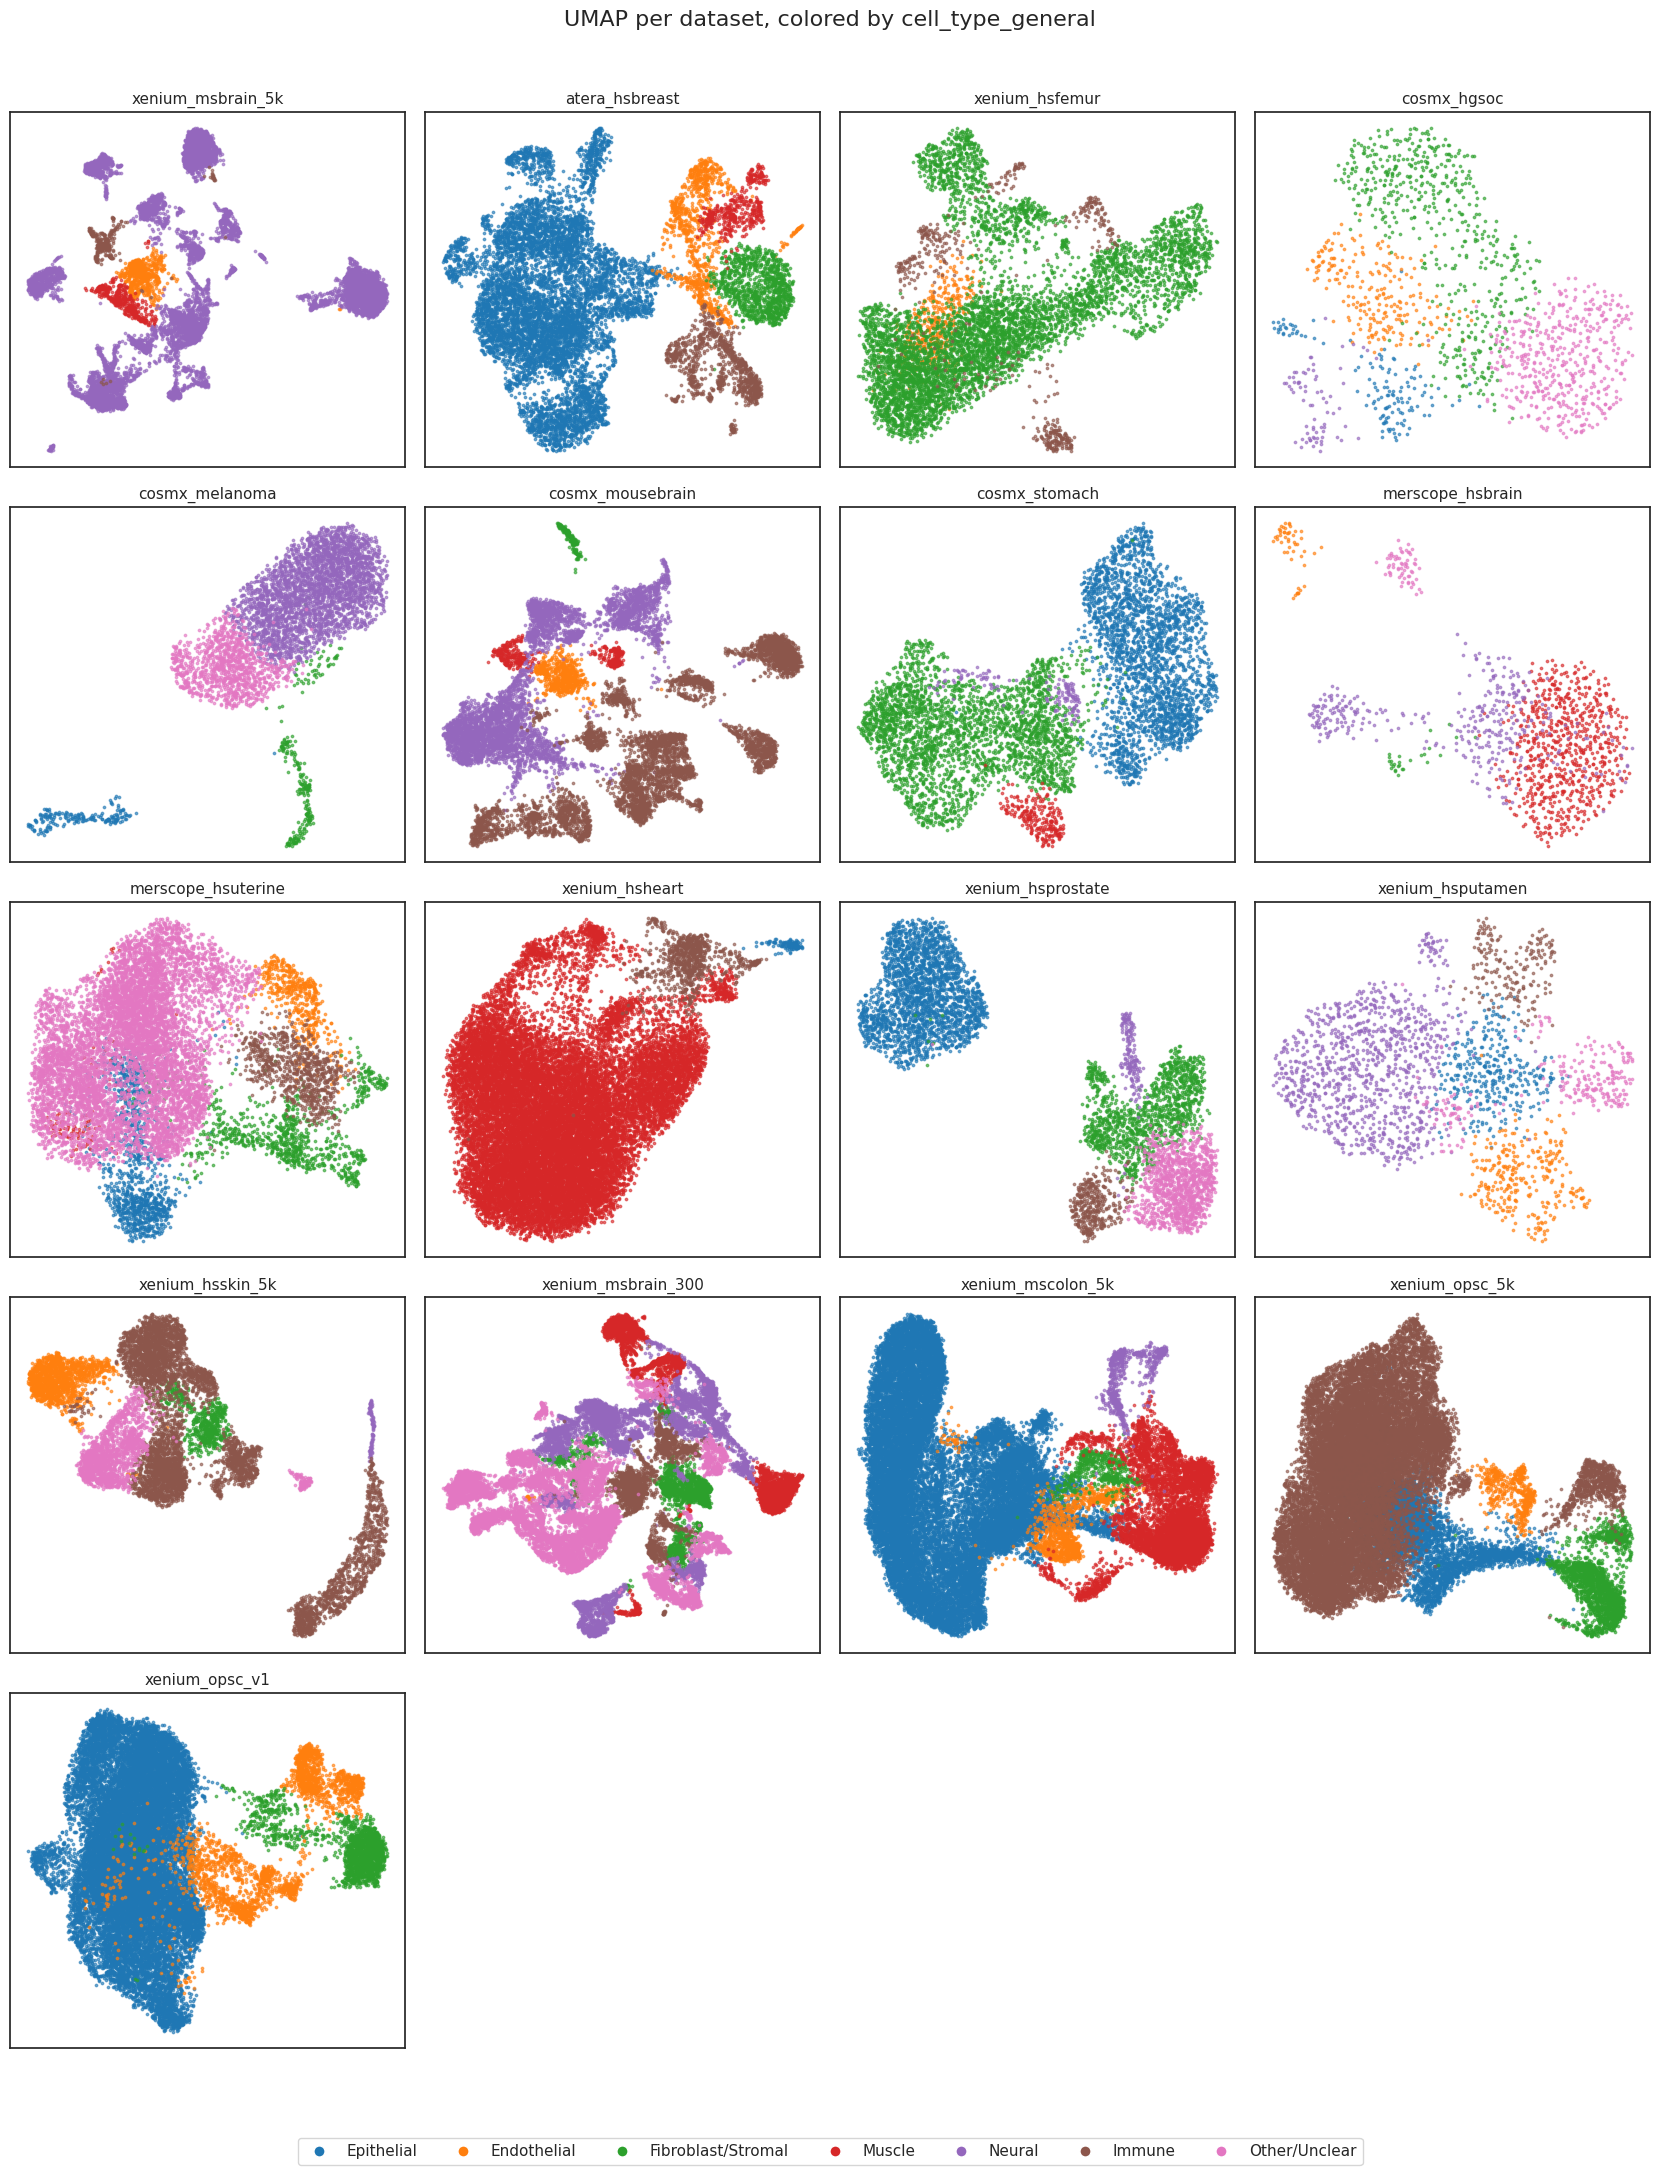

In [11]:
n_datasets = len(DATASET_ORDER)
n_cols = 4
n_rows = int(np.ceil(n_datasets / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 4.2 * n_rows))
axes = axes.flatten()

for ax, name in zip(axes, DATASET_ORDER):
    sub = per_cell[per_cell["dataset"] == name]
    for cat in CATEGORY_ORDER + ["NA"]:
        pts = sub[sub["cell_type_general"] == cat]
        if len(pts) == 0:
            continue
        ax.scatter(
            pts["umap_1"], pts["umap_2"], s=3, alpha=0.6,
            color=CATEGORY_PALETTE.get(cat, "lightgrey"), label=cat, rasterized=True,
        )
    ax.set_title(name, fontsize=11)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")

for ax in axes[n_datasets:]:
    ax.axis("off")

handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=CATEGORY_PALETTE[c], markersize=8, label=c) for c in CATEGORY_ORDER]
fig.legend(handles=handles, loc="lower center", ncol=len(CATEGORY_ORDER), bbox_to_anchor=(0.5, -0.02), fontsize=11)
fig.suptitle("UMAP per dataset, colored by cell_type_general", fontsize=16, y=1.01)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig(f"{FIGURES_DIR}/umap_by_celltype_grid.pdf", bbox_inches="tight", dpi=150)
plt.show()


## Notes / caveats carried forward

- **`Other/Unclear`** cells (no coarse category scored above 0, and not called Immune) are included as their own category throughout. A high `Other/Unclear` share means a large fraction of that dataset's cells currently have no defined cell-type context — check the composition table in section 3 for how big that group actually is per dataset.
- **Malignant vs. normal epithelial cells are not distinguished anywhere**, including atera_hsbreast — see the recap at the top for why.
- This is a **λ=0.5-specific** result for all 16 non-msbrain_5k datasets, computed once. It has not been cross-checked against λ=0.1 or other λ values the way msbrain_5k's robustness was — if this uRNA-burden pattern needs to be defended as robust to λ choice for the manuscript, that would need its own sweep, analogous to the msbrain_5k one.
- `cosmx_pancreas` and `xenium_rcc` are still excluded from all 17 datasets (incomplete base pipeline / unreadable Zarr v3 format respectively) — see `dataset_registry.py`.
